In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Circle, Patch
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans'],
    'axes.unicode_minus': False,
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#DADCE0',
    'axes.labelcolor': '#3C4043',
    'xtick.color': '#5F6368',
    'ytick.color': '#5F6368',
    'text.color': '#202124',
})

C_BLUE = '#2F6BFF'
C_DEEP = '#123B8C'
C_LIGHT = '#7FC0FF'
C_CORAL = '#FF6B6B'
C_TEAL = '#00B39F'
C_TEXT = '#202124'
C_SUB = '#8A94A6'

SAVE = False
OUT_DIR = 'charts_png'


# ================= 通用工具 =================
def clean_ax(ax, grid='y', left=True, bottom=True):
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_visible(left)
    ax.spines['bottom'].set_visible(bottom)
    if left:
        ax.spines['left'].set_color('#DADCE0')
    if bottom:
        ax.spines['bottom'].set_color('#C9CED6')
    if grid:
        ax.grid(axis=grid, color='#EEF1F6', linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=8)


def titles(ax, title, sub, pad=30):
    ax.set_title(title, loc='left', fontsize=17, fontweight='bold', color=C_TEXT, pad=pad)
    ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=10.5, color=C_SUB)


def unit_px(ax):
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    return bb.width / max(abs(x1 - x0), 1e-9), bb.height / max(abs(y1 - y0), 1e-9)


def rounded_path(x, y, w, h, rx=0.0, ry=None, corners='top', ax=None):
    if ry is None:
        if ax is not None and rx > 0:
            px_x, px_y = unit_px(ax)
            ry = rx * px_x / px_y
        else:
            ry = rx
    rx = min(rx, abs(w) / 2)
    ry = min(ry, abs(h))
    k = 0.5523
    V, C = [], []

    def mv(p):
        V.append(p); C.append(Path.MOVETO)

    def ln(p):
        V.append(p); C.append(Path.LINETO)

    def cu(p1, p2, p3):
        V.extend([p1, p2, p3]); C.extend([Path.CURVE4] * 3)

    x2, y2 = x + w, y + h
    rb = ry if corners == 'all' else 0.0
    mv((x, y + rb))
    ln((x, y2 - ry))
    cu((x, y2 - ry + k * ry), (x + rx - k * rx, y2), (x + rx, y2))
    ln((x2 - rx, y2))
    cu((x2 - rx + k * rx, y2), (x2, y2 - ry + k * ry), (x2, y2 - ry))
    ln((x2, y + rb))
    if rb:
        cu((x2, y + rb - k * rb), (x2 - rx + k * rx, y), (x2 - rx, y))
        ln((x + rx, y))
        cu((x + rx - k * rx, y), (x, y + rb - k * rb), (x, y + rb))
    else:
        ln((x, y))
    V.append(V[0]); C.append(Path.CLOSEPOLY)
    return Path(V, C)


def gradient_fill(ax, path, c1, c2, extent, direction='v', zorder=3, alpha=1.0):
    cmap = LinearSegmentedColormap.from_list('grad', [c1, c2])
    g = np.linspace(0, 1, 256)
    img = g.reshape(-1, 1) if direction == 'v' else g.reshape(1, -1)
    im = ax.imshow(img, extent=extent, origin='lower', aspect='auto',
                   cmap=cmap, alpha=alpha, zorder=zorder, interpolation='bilinear')
    clip = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(clip)
    im.set_clip_path(clip)
    return im


def vbar(ax, x, h, w=0.3, c1=C_DEEP, c2=C_LIGHT, bottom=0, r=0.05, zorder=3):
    p = rounded_path(x - w / 2, bottom, w, h - bottom, rx=r, corners='top', ax=ax)
    return gradient_fill(ax, p, c1, c2, (x - w / 2, x + w / 2, bottom, h), 'v', zorder)


def smooth_curve(x, y, n=60):
    """Catmull-Rom 样条插值：不需要 scipy，就能把折线变成 Excel 的「平滑线」。"""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    xs = np.concatenate([[2 * x[0] - x[1]], x, [2 * x[-1] - x[-2]]])
    ys = np.concatenate([[2 * y[0] - y[1]], y, [2 * y[-1] - y[-2]]])
    out_x, out_y = [], []
    for i in range(1, len(xs) - 2):
        p0, p1, p2, p3 = ys[i - 1], ys[i], ys[i + 1], ys[i + 2]
        t = np.linspace(0, 1, n, endpoint=False)
        q = 0.5 * ((2 * p1) + (-p0 + p2) * t + (2 * p0 - 5 * p1 + 4 * p2 - p3) * t ** 2
                   + (-p0 + 3 * p1 - 3 * p2 + p3) * t ** 3)
        out_x.append((xs[i] + (xs[i + 1] - xs[i]) * t)[:-1])
        out_y.append(q[:-1])
    out_x.append([x[-1]])
    out_y.append([y[-1]])
    return np.concatenate(out_x), np.concatenate(out_y)


def gradient_arc(ax, r, t1, t2, lw, c1, c2, n=200, cap=True, zorder=3):
    """用很多小线段拼出带渐变的圆弧；线段用圆头笔触互相重叠，拼接处不会出现锯齿缝隙。"""
    ts = np.linspace(t1, t2, n)
    cmap = LinearSegmentedColormap.from_list('arc', [c1, c2])
    for i in range(n - 1):
        tt = np.radians(ts[i:i + 2])
        ax.plot(r * np.cos(tt), r * np.sin(tt), color=cmap(i / (n - 2)),
                lw=lw, solid_capstyle='round', zorder=zorder)


def gradient_area(ax, x, y, c1, c2, n=600, zorder=1, alpha=1.0):
    """渐变面积：生成一张「曲线以上透明」的 RGBA 渐变图，再贴到坐标系里。
    比逐层填充更平滑，也不会有拼缝。"""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    xs = np.linspace(x0, x1, n)
    yc = np.interp(xs, x, y)
    gy = np.linspace(y0, y1, 256)
    cmap = LinearSegmentedColormap.from_list('area', [c2, c1])
    colors = cmap(np.linspace(0, 1, 256))
    inside = (xs >= x.min()) & (xs <= x.max())      # 数据范围之外不填充
    img = np.zeros((256, n, 4))
    img[..., :3] = colors[:, None, :3]
    img[..., 3] = np.where((gy[:, None] <= yc[None, :]) & inside[None, :], 1.0, 0.0) * alpha
    ax.imshow(img, extent=(x0, x1, y0, y1), origin='lower', aspect='auto',
              zorder=zorder, interpolation='bilinear')


def liquid_ball(ax, pct, c1='#5DD3EA', c2='#1565C0', waves=2, labels=True):
    """水球图：画正弦水面 + 用圆形路径裁剪，再叠加第二层波浪增加层次。"""
    level = -1 + 2 * pct          # 圆的下半部为 0%，上半部为 100%
    x = np.linspace(-1.15, 1.15, 500)
    clip = Circle((0, 0), 1, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(clip)
    for k in range(waves):
        phase = k * 1.9
        amp = 0.06 - 0.018 * k
        freq = 3.0 - 0.7 * k
        y = level + amp * np.sin(freq * x * np.pi + phase)
        col = c1 if k == 0 else c2
        poly = ax.fill_between(x, -1.35, y, color=col,
                               alpha=0.5 if k == 0 else 0.94, zorder=2 + k, lw=0)
        poly.set_clip_path(clip)
    # 外圈轮廓最后画，保证边线不被水面盖住
    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), color='#B9C7DA', lw=2.2, zorder=9)
    ax.set_xlim(-1.12, 1.12)
    ax.set_ylim(-1.12, 1.12)
    ax.set_aspect('equal')
    ax.axis('off')
    if labels:
        ax.text(0, 0.02, f'{pct:.0%}', ha='center', va='center', fontsize=30,
                fontweight='bold', color='white' if pct > 0.3 else '#1B3A6B', zorder=10)
        ax.text(0, -0.22, '完成率', ha='center', va='center', fontsize=10.5,
                color='white' if pct > 0.3 else '#5B6B85', zorder=10)


def finish(fig, name):
    if SAVE:
        os.makedirs(OUT_DIR, exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', facecolor='white')
    plt.show()

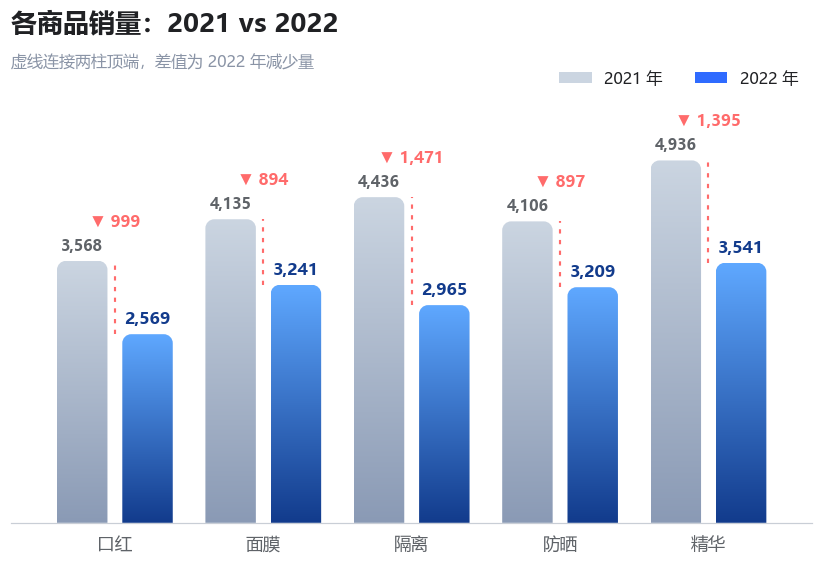

In [2]:
df9 = pd.DataFrame({'商品': ['口红', '面膜', '隔离', '防晒', '精华'],
                    '2021销量': [3568, 4135, 4436, 4106, 4936],
                    '2022销量': [2569, 3241, 2965, 3209, 3541]})
df9['差值'] = df9['2021销量'] - df9['2022销量']

fig, ax = plt.subplots(figsize=(9.4, 5.2))
ax.set_xlim(-0.7, len(df9) - 0.3)
ax.set_ylim(0, 6000)
w, off = 0.34, 0.22

for i, row in df9.iterrows():
    vbar(ax, i - off, row['2021销量'], w=w, c1='#8A9AB5', c2='#CBD5E1', r=0.06)
    vbar(ax, i + off, row['2022销量'], w=w, c1='#123B8C', c2='#5FA8FF', r=0.06)
    ax.text(i - off, row['2021销量'] + 90, f'{row["2021销量"]:,}', ha='center', va='bottom',
            fontsize=10, color='#5F6368', fontweight='bold')
    ax.text(i + off, row['2022销量'] + 90, f'{row["2022销量"]:,}', ha='center', va='bottom',
            fontsize=11, color='#123B8C', fontweight='bold')
    # 差值：两根柱子之间的虚线 + 顶部差值标签
    ax.plot([i, i], [row['2022销量'], row['2021销量']], ls=(0, (2, 3)),
            color=C_CORAL, lw=1.4, zorder=6)
    ax.text(i, row['2021销量'] + 420, f'▼ {row["差值"]:,}', ha='center', va='bottom',
            fontsize=10.5, color=C_CORAL, fontweight='bold')

ax.set_xticks(range(len(df9)))
ax.set_xticklabels(df9['商品'], fontsize=11.5)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
ax.legend(handles=[Patch(fc='#CBD5E1', label='2021 年'), Patch(fc='#2F6BFF', label='2022 年')],
          loc='upper right', ncol=2, frameon=False, fontsize=10.5, bbox_to_anchor=(1.0, 1.06))
titles(ax, '各商品销量：2021 vs 2022', '虚线连接两柱顶端，差值为 2022 年减少量', pad=34)
finish(fig, 'case09_compare_bar')

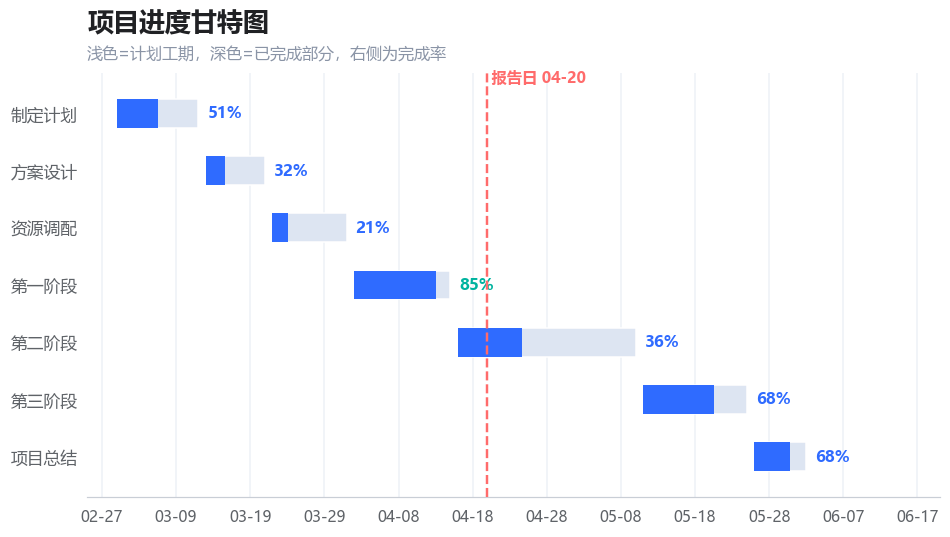

In [3]:
df10 = pd.DataFrame({
    '项目名称': ['制定计划', '方案设计', '资源调配', '第一阶段', '第二阶段', '第三阶段', '项目总结'],
    '开始日期': pd.to_datetime(['2022-03-01', '2022-03-13', '2022-03-22', '2022-04-02',
                            '2022-04-16', '2022-05-11', '2022-05-26']),
    '项目天数': [11, 8, 10, 13, 24, 14, 7],
    '完成度': [0.51, 0.32, 0.21, 0.85, 0.36, 0.68, 0.68],
})
df10['进行天数'] = df10['项目天数'] * df10['完成度']
df10['结束日期'] = df10['开始日期'] + pd.to_timedelta(df10['项目天数'], unit='D')

fig, ax = plt.subplots(figsize=(10, 5.0))
y = np.arange(len(df10))
x0 = mdates.date2num(df10['开始日期'])
ax.set_ylim(-0.7, len(df10) - 0.3)
ax.invert_yaxis()

for i, row in df10.iterrows():
    left = mdates.date2num(row['开始日期'])
    ax.barh(i, row['项目天数'], left=left, height=0.5, color='#DDE5F2',
            edgecolor='white', zorder=2)
    ax.barh(i, row['进行天数'], left=left, height=0.5, color=C_BLUE, zorder=3)
    ax.text(mdates.date2num(row['结束日期']) + 1.2, i, f'{row["完成度"]:.0%}',
            va='center', ha='left', fontsize=10.5, fontweight='bold',
            color=C_BLUE if row['完成度'] < 0.8 else C_TEAL)

ax.set_yticks(y)
ax.set_yticklabels(df10['项目名称'], fontsize=11)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
ax.set_xlim(mdates.date2num(pd.Timestamp('2022-02-25')),
            mdates.date2num(pd.Timestamp('2022-06-20')))
clean_ax(ax, grid='x', left=False)
ax.tick_params(axis='y', length=0, pad=6)

ax.axvline(mdates.date2num(pd.Timestamp('2022-04-20')), color=C_CORAL, lw=1.6, ls='--', zorder=5)
ax.text(mdates.date2num(pd.Timestamp('2022-04-20')), -0.62, ' 报告日 04-20',
        color=C_CORAL, fontsize=10, fontweight='bold', va='center')
titles(ax, '项目进度甘特图', '浅色=计划工期，深色=已完成部分，右侧为完成率', pad=28)
finish(fig, 'case10_gantt')

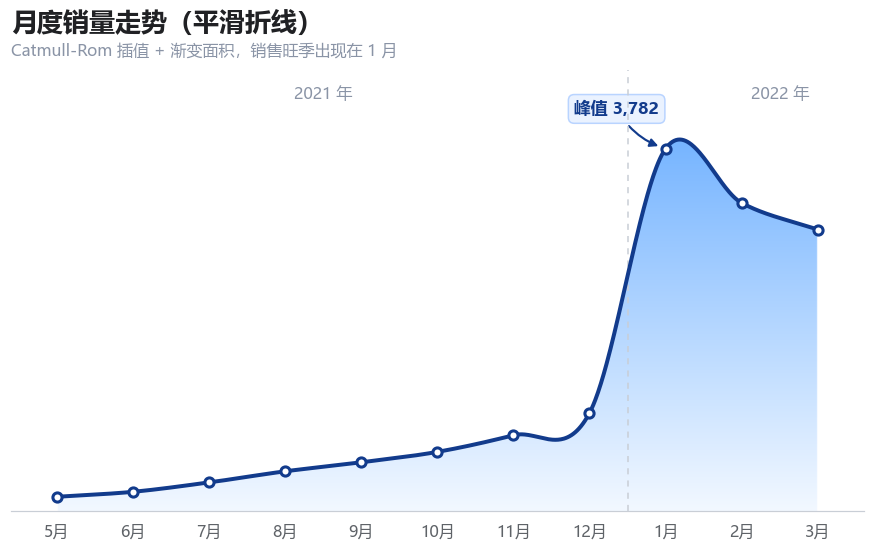

In [4]:
df11 = pd.DataFrame({
    '年份': [2021] * 8 + [2022] * 3,
    '月份': ['5月', '6月', '7月', '8月', '9月', '10月', '11月', '12月', '1月', '2月', '3月'],
    '销量': [146, 198, 296, 412, 506, 615, 789, 1021, 3782, 3215, 2936],
})

x = np.arange(len(df11))
sx, sy = smooth_curve(x, df11['销量'], n=80)

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.set_xlim(-0.6, len(df11) - 0.4)
ax.set_ylim(0, 4600)

# 渐变面积：曲线以上透明，下方由浅到深
gradient_area(ax, sx, sy, c1='#5FA8FF', c2='#F2F8FF', zorder=1)
ax.plot(sx, sy, color=C_DEEP, lw=2.6, zorder=4, solid_capstyle='round')
ax.plot(x, df11['销量'], 'o', ms=6, mfc='white', mec=C_DEEP, mew=2, zorder=5)

# 峰值标注
imax = int(df11['销量'].idxmax())
ax.annotate(f'峰值 {df11["销量"].iloc[imax]:,}', xy=(imax, df11['销量'].iloc[imax]),
            xytext=(imax - 1.2, 4150), fontsize=11, fontweight='bold', color=C_DEEP,
            bbox=dict(boxstyle='round,pad=0.35', fc='#EAF2FF', ec='#B9D4FF', lw=1),
            arrowprops=dict(arrowstyle='-|>', color=C_DEEP, lw=1.4,
                            connectionstyle='arc3,rad=0.2', shrinkB=5))

# 年份分隔
ax.axvline(7.5, color='#C9CED6', lw=1, ls=(0, (4, 4)), zorder=3)
ax.text(3.5, 4300, '2021 年', ha='center', fontsize=10.5, color=C_SUB)
ax.text(9.5, 4300, '2022 年', ha='center', fontsize=10.5, color=C_SUB)

ax.set_xticks(x)
ax.set_xticklabels(df11['月份'], fontsize=10.5)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
titles(ax, '月度销量走势（平滑折线）', 'Catmull-Rom 插值 + 渐变面积，销售旺季出现在 1 月', pad=26)
finish(fig, 'case11_smooth_line')

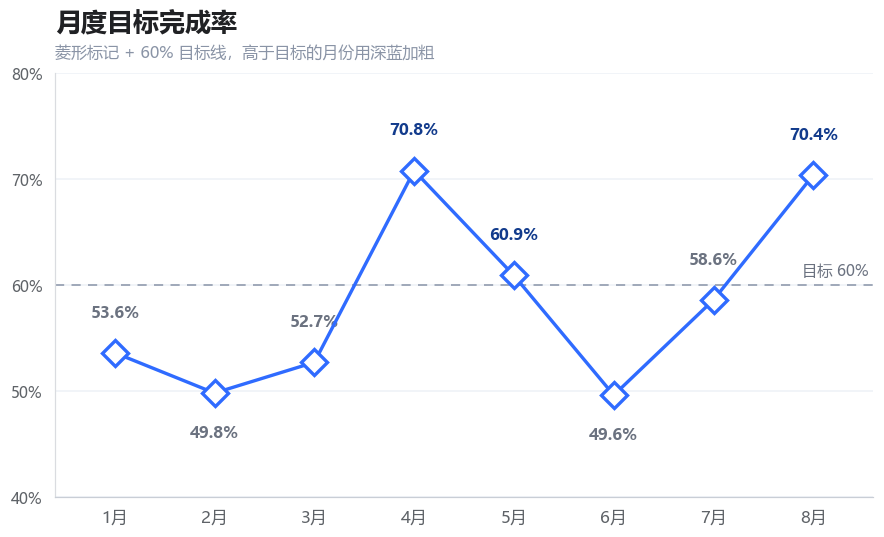

In [5]:
df12 = pd.DataFrame({'月份': ['1月', '2月', '3月', '4月', '5月', '6月', '7月', '8月'],
                     '完成率': [0.536, 0.498, 0.527, 0.708, 0.609, 0.496, 0.586, 0.704]})

fig, ax = plt.subplots(figsize=(9.6, 5.0))
ax.set_xlim(-0.6, len(df12) - 0.4)
ax.set_ylim(0.40, 0.80)

ax.plot(range(len(df12)), df12['完成率'], color=C_BLUE, lw=2.2,
        marker='D', ms=12, mfc='white', mec=C_BLUE, mew=2.2, zorder=4)
ax.axhline(0.60, color='#9AA4B5', lw=1.2, ls=(0, (5, 4)), zorder=2)
ax.text(len(df12) - 0.45, 0.605, '目标 60%', ha='right', va='bottom', fontsize=10, color='#6B7280')

for i, v in enumerate(df12['完成率']):
    prev = df12['完成率'].iloc[i - 1] if i > 0 else v
    nxt = df12['完成率'].iloc[i + 1] if i < len(df12) - 1 else v
    is_min = v < prev and v < nxt
    dy = -0.030 if is_min else 0.030
    ax.text(i, v + dy, f'{v:.1%}', ha='center', va='top' if dy < 0 else 'bottom',
            fontsize=10.5, fontweight='bold',
            color=C_DEEP if v >= 0.6 else '#6B7280',
            bbox=dict(boxstyle='round,pad=0.18', fc='white', ec='none', alpha=0.9))

ax.set_xticks(range(len(df12)))
ax.set_xticklabels(df12['月份'], fontsize=11)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8])
clean_ax(ax, grid='y')
titles(ax, '月度目标完成率', '菱形标记 + 60% 目标线，高于目标的月份用深蓝加粗', pad=28)
finish(fig, 'case12_diamond_line')

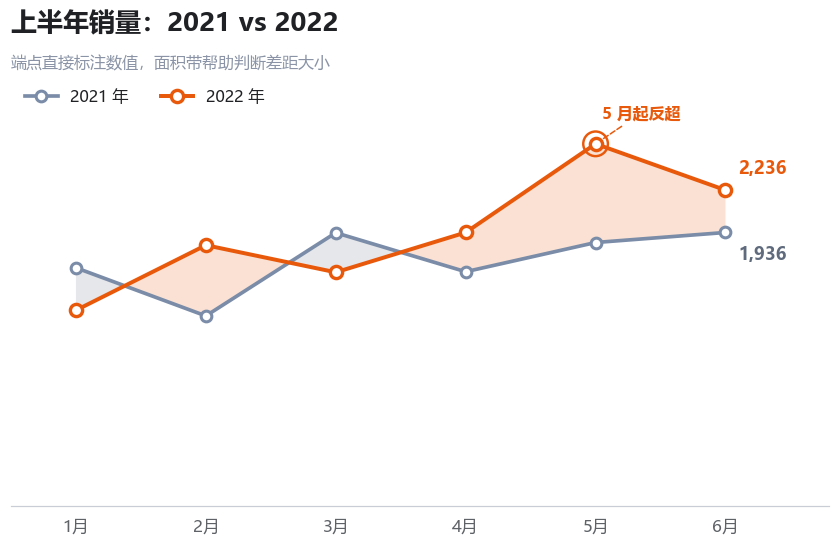

In [6]:
df13 = pd.DataFrame({'月份': ['1月', '2月', '3月', '4月', '5月', '6月'],
                     '2021年': [1686, 1345, 1934, 1658, 1865, 1936],
                     '2022年': [1385, 1846, 1654, 1936, 2564, 2236]})

fig, ax = plt.subplots(figsize=(9.6, 5.0))
x = np.arange(len(df13))
ax.set_xlim(-0.5, len(df13) - 0.2)
ax.set_ylim(0, 3000)

# 只填充两条线之间的「差距」，比整体面积更干净
ax.fill_between(x, df13['2021年'], df13['2022年'], where=df13['2022年'] >= df13['2021年'],
                interpolate=True, color='#E8590C', alpha=0.18, zorder=1, lw=0)
ax.fill_between(x, df13['2021年'], df13['2022年'], where=df13['2021年'] >= df13['2022年'],
                interpolate=True, color='#5F6B7D', alpha=0.16, zorder=1, lw=0)

ax.plot(x, df13['2021年'], color='#7A8CA8', lw=2.4, marker='o', ms=7,
        mfc='white', mew=2, zorder=3, label='2021 年')
ax.plot(x, df13['2022年'], color='#E8590C', lw=2.6, marker='o', ms=8,
        mfc='white', mew=2.2, zorder=4, label='2022 年')

# 末端标签：一个在上、一个在下，避免叠在一起
ax.text(x[-1] + 0.1, df13['2022年'].iloc[-1] + 90, f'{df13["2022年"].iloc[-1]:,}',
        va='bottom', fontsize=11.5, fontweight='bold', color='#E8590C')
ax.text(x[-1] + 0.1, df13['2021年'].iloc[-1] - 90, f'{df13["2021年"].iloc[-1]:,}',
        va='top', fontsize=11.5, fontweight='bold', color='#5F6B7D')

# 5 月反超点高亮
ax.scatter([4], [df13['2022年'].iloc[4]], s=260, facecolor='none',
           edgecolor='#E8590C', lw=1.6, zorder=5)
ax.annotate('5 月起反超', xy=(4, df13['2022年'].iloc[4]), xytext=(4.05, 2750),
            fontsize=10.5, color='#E8590C', fontweight='bold', ha='left',
            arrowprops=dict(arrowstyle='-', color='#E8590C', lw=1, ls='--'))

ax.set_xticks(x)
ax.set_xticklabels(df13['月份'], fontsize=11)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
ax.legend(loc='upper left', ncol=2, frameon=False, fontsize=10.5, bbox_to_anchor=(0, 1.02))
titles(ax, '上半年销量：2021 vs 2022', '端点直接标注数值，面积带帮助判断差距大小', pad=34)
finish(fig, 'case13_compare_line')

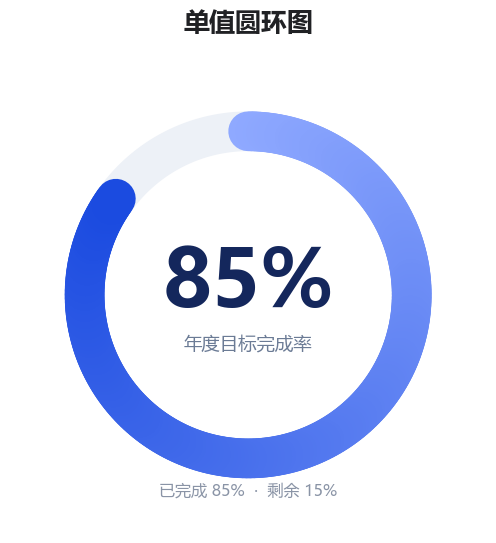

In [7]:
pct = 0.85
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.set_xlim(-1.45, 1.45)
ax.set_ylim(-1.45, 1.45)
ax.set_aspect('equal')
ax.axis('off')

# 底环（整圈，浅灰）
ax.plot(np.cos(np.linspace(0, 2 * np.pi, 400)), np.sin(np.linspace(0, 2 * np.pi, 400)),
        color='#EDF1F7', lw=26, solid_capstyle='butt', zorder=1)
# 数值弧：从 90° 顺时针扫过 pct * 360°
gradient_arc(ax, 1.0, 90, 90 - 360 * pct, 26, '#8FA9FF', '#1B4BE0', n=240, zorder=3)

ax.text(0, 0.06, f'{pct:.0%}', ha='center', va='center', fontsize=52,
        fontweight='bold', color='#14275C')
ax.text(0, -0.30, '年度目标完成率', ha='center', va='center', fontsize=12, color='#6B7B95')
ax.text(0, -1.22, f'已完成 {pct*100:.0f}%  ·  剩余 {(1-pct)*100:.0f}%',
        ha='center', fontsize=10.5, color=C_SUB)

ax.set_title('单值圆环图', fontsize=17, fontweight='bold', color=C_TEXT, pad=18)
finish(fig, 'case14_single_donut')

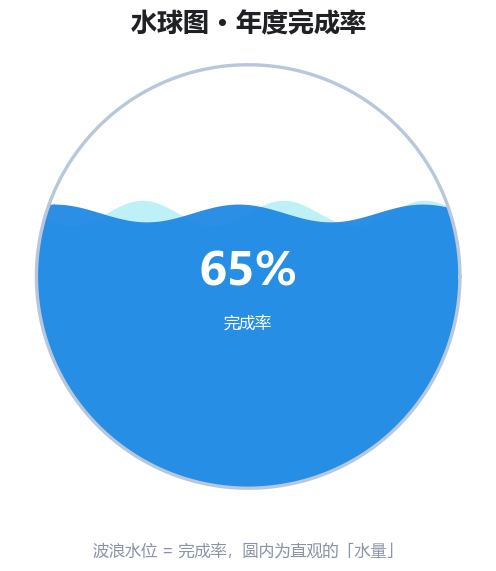

In [8]:
pct = 0.65
fig, ax = plt.subplots(figsize=(5.6, 5.6))
liquid_ball(ax, pct, c1='#7FE3F0', c2='#1E88E5')
ax.set_title('水球图 · 年度完成率', fontsize=17, fontweight='bold', color=C_TEXT, pad=6)
ax.text(0, -1.32, '波浪水位 = 完成率，圆内为直观的「水量」',
        ha='center', fontsize=10.5, color=C_SUB)
finish(fig, 'case15_liquid_ball')